# Olist E-Commerce: SQL Analysis

**Research question:** Which product categories and sellers drive the most revenue on Olist's marketplace, and does late delivery measurably hurt customer review scores?

This notebook runs the queries in `sql/02_analysis_queries.sql` against `olist.db` (built from the raw CSVs by `build_database.py`) and visualizes the results. The SQL itself -- joins, CTEs, window functions, CASE-based bucketing -- lives in the `.sql` file; this notebook is the execution + visualization layer on top of it.

### Business questions

1. How is revenue trending month over month, and where did growth accelerate or stall?
2. Which product categories generate the most revenue -- and do the highest-revenue categories also have the happiest customers?
3. Does a late delivery measurably hurt the customer's review score, and how much of our order volume is actually affected?
4. Which sellers generate the most revenue, and does being a top earner also mean delivering a good customer experience?

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('olist.db')
pd.set_option('display.max_columns', None)

## Data quality note

Before trusting any aggregate here, it's worth surfacing one issue found while building the schema: **`review_id` is not unique** in the source data -- 827 of ~100,000 rows reuse an existing `review_id` (most plausibly a re-submitted or updated review). Because of this, `review_id` is *not* used as a primary key in the schema (see `sql/01_schema.sql`); it's kept as a plain column. It doesn't affect the queries below since none of them key off `review_id` directly, but it's the kind of thing you'd want to flag before anyone built a reviews-deduplication report on top of this table.

In [2]:
dups = pd.read_sql('''
    SELECT review_id, COUNT(*) AS n
    FROM order_reviews
    GROUP BY review_id
    HAVING COUNT(*) > 1
''', conn)
print(f"{len(dups)} review_id values appear more than once")
dups.head()

802 review_id values appear more than once


,review_id,n
0,00130cbe1f9d422698c812ed8ded1919,2
1,0115633a9c298b6a98bcbe4eee75345f,2
2,0174caf0ee5964646040cd94e15ac95e,2
3,017808d29fd1f942d97e50184dfb4c13,2
4,0254bd905dc677a6078990aad3331a36,2


## Query 1: Monthly revenue trend

**Business question:** How is revenue trending month over month, and where did growth accelerate or stall?

Revenue is `SUM(order_items.price)` for delivered orders, grouped by purchase month. A `LAG()` window function computes percent change vs. the prior month directly in SQL.

The dataset ramps up slowly: only a handful of orders exist before 2017, so the trend chart below starts at 2017-01 to avoid a misleading spike from a near-empty early month.

In [3]:
query1 = """
WITH monthly_revenue AS (
    SELECT
        strftime('%Y-%m', o.order_purchase_timestamp) AS order_month,
        ROUND(SUM(oi.price), 2)                        AS revenue,
        COUNT(DISTINCT o.order_id)                     AS orders
    FROM orders o
    JOIN order_items oi ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY order_month
)
SELECT
    order_month,
    revenue,
    orders,
    ROUND(
        100.0 * (revenue - LAG(revenue) OVER (ORDER BY order_month))
        / LAG(revenue) OVER (ORDER BY order_month),
        1
    ) AS pct_change_vs_prior_month
FROM monthly_revenue
ORDER BY order_month;
"""
monthly = pd.read_sql(query1, conn)
monthly.head()

,order_month,revenue,orders,pct_change_vs_prior_month
0,2016-09,134.97,1,NaN
1,2016-10,40325.11,265,29777.1
2,2016-12,10.90,1,-100.0
3,2017-01,111798.36,750,1025573.0
4,2017-02,234223.40,1653,109.5


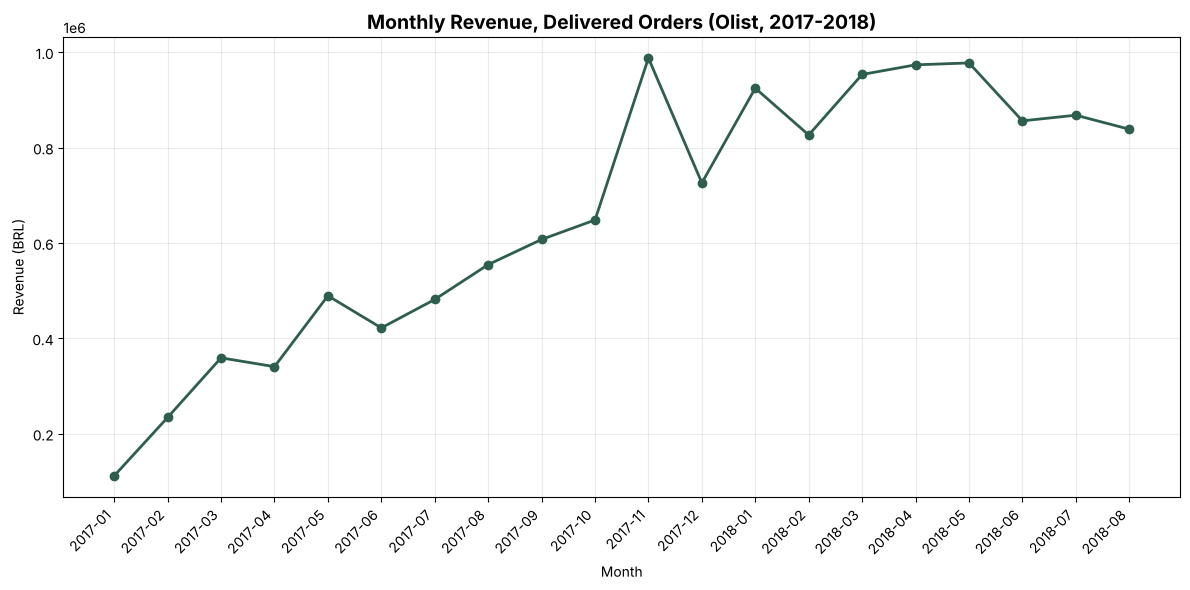

In [4]:
plot_df = monthly[monthly['order_month'] >= '2017-01'].copy()

plt.figure(figsize=(12, 6))
plt.plot(plot_df['order_month'], plot_df['revenue'], marker='o', color='#2E5E4E', linewidth=2)
plt.title('Monthly Revenue, Delivered Orders (Olist, 2017-2018)', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue (BRL)')
plt.xticks(rotation=45, ha='right')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('screenshots/viz1_monthly_revenue_trend.png', dpi=150)
plt.show()

Revenue grows steadily from early 2017 through late 2017, then roughly plateaus through most of 2018 -- consistent with a marketplace scaling up its seller base and then stabilizing. The sharp drop in the final month is an artifact of the dataset's cutoff (partial month of data), not a real demand drop.

## Query 2: Top 10 product categories by revenue

**Business question:** Which product categories generate the most revenue -- and do the highest-revenue categories also have the happiest customers?

Joins `order_items -> products -> category_translation` to get English category names (the raw column is Portuguese), and reports each category's average review score alongside its revenue.

In [5]:
query2 = """
WITH category_revenue AS (
    SELECT
        COALESCE(ct.product_category_name_english, p.product_category_name, 'unknown') AS category,
        SUM(oi.price)             AS revenue,
        COUNT(*)                  AS items_sold
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    JOIN products p ON p.product_id = oi.product_id
    LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY category
),
category_reviews AS (
    SELECT
        COALESCE(ct.product_category_name_english, p.product_category_name, 'unknown') AS category,
        AVG(r.review_score) AS avg_review_score
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    JOIN products p ON p.product_id = oi.product_id
    LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
    JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY category
)
SELECT
    cr.category,
    ROUND(cr.revenue, 2)       AS revenue,
    cr.items_sold,
    ROUND(crev.avg_review_score, 2) AS avg_review_score
FROM category_revenue cr
JOIN category_reviews crev ON crev.category = cr.category
ORDER BY cr.revenue DESC
LIMIT 10;
"""
categories = pd.read_sql(query2, conn)
categories

,category,revenue,items_sold,avg_review_score
0,health_beauty,1233131.72,9465,4.18
1,watches_gifts,1166176.98,5859,4.06
2,bed_bath_table,1023434.76,10953,3.90
3,sports_leisure,954852.55,8431,4.15
4,computers_accessories,888724.61,7644,3.98
5,furniture_decor,711927.69,8160,3.93
6,housewares,615628.69,6795,4.10
7,cool_stuff,610204.10,3718,4.18
8,auto,578966.65,4140,4.09
9,toys,471286.48,4030,4.19


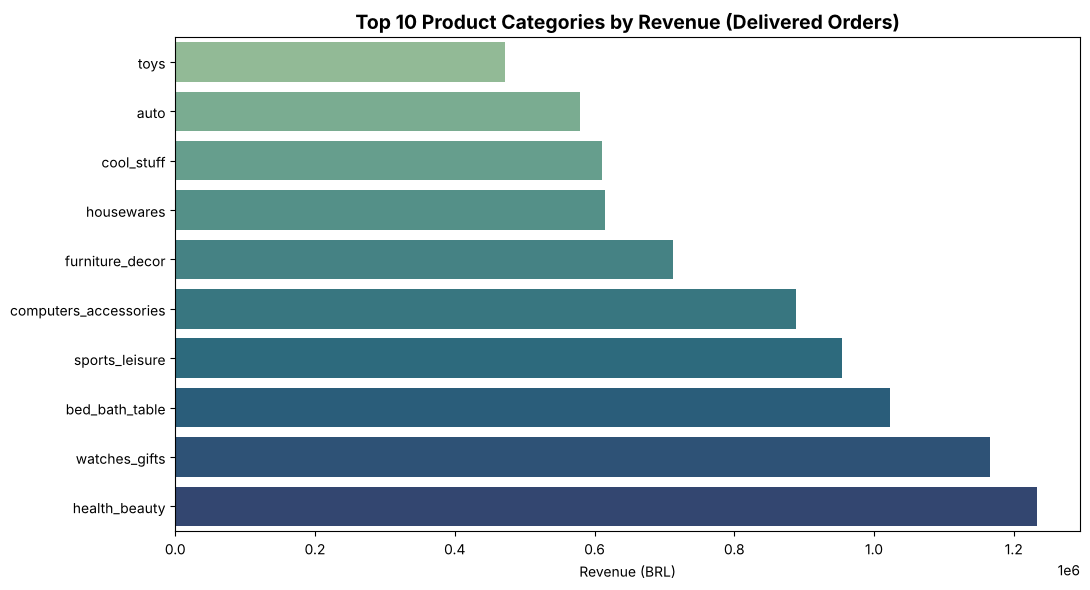

In [6]:
plt.figure(figsize=(11, 6))
sns.barplot(data=categories.sort_values('revenue'), x='revenue', y='category',
            hue='category', palette='crest', legend=False)
plt.title('Top 10 Product Categories by Revenue (Delivered Orders)', fontsize=14, fontweight='bold')
plt.xlabel('Revenue (BRL)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('screenshots/viz2_top_categories_revenue.png', dpi=150)
plt.show()

`health_beauty` and `watches_gifts` lead on revenue, narrowly ahead of `bed_bath_table`. Average review scores across these top categories sit in a fairly tight 3.9-4.2 band -- so at the category level, what sells the most isn't strongly tied to how happy customers are with it. That makes the next question more interesting: if category doesn't explain satisfaction, does *delivery performance*?

## Query 3: Delivery delay vs. customer review score (the headline finding)

**Business question:** Does a late delivery measurably hurt the customer's review score, and how much of our order volume is actually affected?

Buckets every delivered order by `delivered_date - estimated_delivery_date` (negative/zero = on time or early, positive = late), then averages `review_score` within each bucket. This directly tests whether an operational metric (on-time delivery) drives a customer-experience metric (star rating).

In [7]:
query3 = """
WITH delivery AS (
    SELECT
        o.order_id,
        CAST(julianday(o.order_delivered_customer_date) - julianday(o.order_estimated_delivery_date) AS INTEGER) AS delay_days
    FROM orders o
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
),
bucketed AS (
    SELECT
        d.order_id,
        r.review_score,
        CASE
            WHEN d.delay_days <= -7 THEN '1. Early (7+ days)'
            WHEN d.delay_days <= 0  THEN '2. On time'
            WHEN d.delay_days <= 7  THEN '3. Late (1-7 days)'
            ELSE                         '4. Very late (8+ days)'
        END AS delivery_bucket
    FROM delivery d
    JOIN order_reviews r ON r.order_id = d.order_id
)
SELECT
    delivery_bucket,
    COUNT(*)                        AS num_orders,
    ROUND(AVG(review_score), 2)     AS avg_review_score,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_orders
FROM bucketed
GROUP BY delivery_bucket
ORDER BY delivery_bucket;
"""
delivery = pd.read_sql(query3, conn)
delivery

,delivery_bucket,num_orders,avg_review_score,pct_of_orders
0,1. Early (7+ days),71716,4.31,73.9
1,2. On time,18729,4.18,19.3
2,3. Late (1-7 days),3684,2.69,3.8
3,4. Very late (8+ days),2878,1.69,3.0


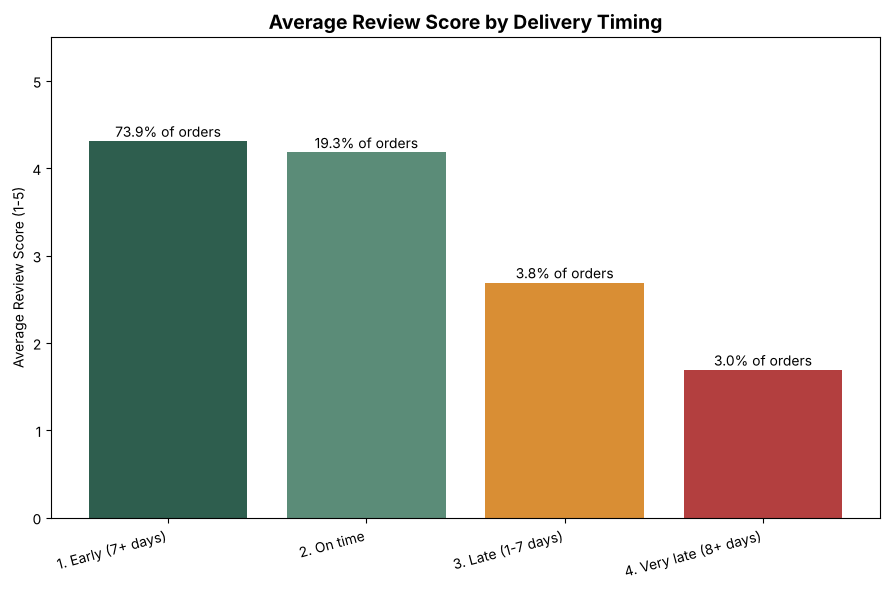

In [8]:
plt.figure(figsize=(9, 6))
colors = ['#2E5E4E', '#5B8C78', '#D98E34', '#B33F3F']
bars = plt.bar(delivery['delivery_bucket'], delivery['avg_review_score'], color=colors)
for bar, pct in zip(bars, delivery['pct_of_orders']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
              f"{pct}% of orders", ha='center', fontsize=10)
plt.title('Average Review Score by Delivery Timing', fontsize=14, fontweight='bold')
plt.ylabel('Average Review Score (1-5)')
plt.xlabel('')
plt.xticks(rotation=15, ha='right')
plt.ylim(0, 5.5)
plt.tight_layout()
plt.savefig('screenshots/viz3_delivery_vs_review_score.png', dpi=150)
plt.show()

This is the clearest signal in the whole analysis. Orders delivered early or on time average **4.2-4.3 stars**, but that collapses once an order runs late -- down to roughly **2.7 stars** for 1-7 days late, and even lower beyond that. Fortunately, late deliveries are the minority (late orders are a small share of the ~94k reviewed deliveries here), but for the sellers and categories experiencing them, delivery delay is very plausibly the single biggest lever on customer satisfaction -- bigger than which product category was ordered.

## Query 4: Top 10 sellers by revenue (ranked, with order volume and review score)

**Business question:** Which sellers generate the most revenue, and does being a top earner also mean delivering a good customer experience?

Uses `RANK()` to order sellers by revenue, and a `HAVING` clause to exclude sellers with fewer than 20 orders (too little data to trust their average review score).

In [9]:
query4 = """
WITH seller_stats AS (
    SELECT
        oi.seller_id,
        s.seller_state,
        SUM(oi.price)        AS revenue,
        COUNT(DISTINCT oi.order_id) AS num_orders,
        AVG(r.review_score)  AS avg_review_score
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    JOIN sellers s ON s.seller_id = oi.seller_id
    JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY oi.seller_id, s.seller_state
    HAVING COUNT(DISTINCT oi.order_id) >= 20
)
SELECT
    RANK() OVER (ORDER BY revenue DESC) AS revenue_rank,
    seller_id,
    seller_state,
    ROUND(revenue, 2) AS revenue,
    num_orders,
    ROUND(avg_review_score, 2) AS avg_review_score
FROM seller_stats
ORDER BY revenue_rank
LIMIT 10;
"""
sellers = pd.read_sql(query4, conn)
sellers

,revenue_rank,seller_id,seller_state,revenue,num_orders,avg_review_score
0,1,4869f7a5dfa277a7dca6462dcf3b52b2,SP,226987.93,1124,4.13
1,2,53243585a1d6dc2643021fd1853d8905,BA,217940.44,348,4.12
2,3,4a3ca9315b744ce9f8e9374361493884,SP,199408.32,1772,3.80
3,4,fa1c13f2614d7b5c4749cbc52fecda94,SP,190917.14,578,4.36
4,5,7c67e1448b00f6e969d365cea6b010ab,SP,188063.83,973,3.35
5,6,7e93a43ef30c4f03f38b393420bc753a,SP,165981.49,319,4.35
6,7,da8622b14eb17ae2831f4ac5b9dab84a,SP,162303.67,1311,4.07
7,8,7a67c85e85bb2ce8582c35f2203ad736,SP,140238.65,1145,4.25
8,9,1025f0e2d44d7041d6cf58b6550e0bfa,SP,139720.16,910,3.85
9,10,955fee9216a65b617aa5c0531780ce60,SP,131906.71,1261,4.08


The top seller by revenue (state SP) also carries one of the healthier review scores among this group (4.13), while rank #3 -- similar order volume -- sits noticeably lower at 3.80. Revenue rank and review score clearly aren't the same axis; a seller can move a lot of product and still be underperforming on the experience they deliver, which circles back to the delivery-timing finding above as the likely explanation.

## Reflection

Given more time, I'd want to: (1) pull in the `geolocation` table (left out of this analysis) to check whether delivery delay correlates with seller-customer distance rather than seller behavior itself; (2) run the delivery-delay-vs-review-score relationship as a proper regression controlling for category and seller, instead of a simple bucketed average, to see how much of the effect survives; and (3) look at `payment_installments` against order value and review score, since prior retail research suggests financing friction is its own satisfaction lever independent of delivery.